# Agreement analysis: Bland-Altman, MAE, MAPE

This notebook computes agreement statistics between VO2 max estimates from Apple Watch Series 10 (index measure) and indirect calorimetry (COSMED; criterion measure). We calculate Bland-Altman limits of agreement, mean absolute error (MAE), and mean absolute percentage error (MAPE).

#### First, import necessary libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import t
from scipy import stats
import plotly.express as px

## 1. Data exploration and processing

Write file path and read using ``pandas``

In [2]:
file_path = 'vo2max_data.csv'
df = pd.read_csv(file_path)

Explore data.

In [3]:
df.head()

,participant_id,sex,applewatch_model,vo2max_attained,include_vo2,cosmed_vo2max,applewatch_vo2max,cosmed_crf_percentile_friend
0,participant01,m,S10,Yes,yes,61.23,59.9,90
1,participant02,m,S10,Yes,yes,59.60,57.7,90
2,participant03,f,S10,Yes,yes,42.88,37.7,70
3,participant04,f,S10,Yes,yes,41.67,45.5,60
4,participant05,f,S10,Yes,yes,46.33,44.3,80


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   participant_id                40 non-null     object 
 1   sex                           40 non-null     object 
 2   applewatch_model              40 non-null     object 
 3   vo2max_attained               40 non-null     object 
 4   include_vo2                   40 non-null     object 
 5   cosmed_vo2max                 40 non-null     float64
 6   applewatch_vo2max             40 non-null     object 
 7   cosmed_crf_percentile_friend  40 non-null     int64  
dtypes: float64(1), int64(1), object(6)
memory usage: 2.6+ KB


### Data processing for VO2 max

We'll need to drop participants who failed to attain true VO2 max during criterion testing. We'll also have to drop participants with missing VO2 max values for either the criterion or index measure. Let's first look at how many participants we can expect to drop out of our complete participant set (40 participants).

We can see below the number of participants that met inclusion criteria for VO2 max analysis.

In [5]:
df['include_vo2'].value_counts()

include_vo2
yes    35
no      5
Name: count, dtype: int64

Let's convert the VO2 max values to dtype ``numeric``, using ``errors='coerce'``, which inserts NaN for null values. These NaN values are the missing values that we will remove for analysis.

In [6]:
df['cosmed_vo2max'] = pd.to_numeric(df['cosmed_vo2max'], errors='coerce')
df['applewatch_vo2max'] = pd.to_numeric(df['applewatch_vo2max'], errors='coerce')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   participant_id                40 non-null     object 
 1   sex                           40 non-null     object 
 2   applewatch_model              40 non-null     object 
 3   vo2max_attained               40 non-null     object 
 4   include_vo2                   40 non-null     object 
 5   cosmed_vo2max                 40 non-null     float64
 6   applewatch_vo2max             36 non-null     float64
 7   cosmed_crf_percentile_friend  40 non-null     int64  
dtypes: float64(2), int64(1), object(5)
memory usage: 2.6+ KB


#### Drop NaN values 

In [7]:
df = df.dropna(subset=['applewatch_vo2max', 'cosmed_vo2max'])

#### Drop participants who didn't attain VO2max

In [8]:
df = df.loc[df['include_vo2'] == 'yes']

### Define criterion and index measures

Now it's time to specify the criterion and index measures. This part can be reproducible across different devices, whereas cleaning and preprocessing typically requires you to adapt to your given data. 

Here, we'll do the VO2 max analysis.

In [9]:
criterion = df['cosmed_vo2max']
index = df['applewatch_vo2max']

Define unit for plot

In [10]:
unit = 'mL/kg/min'
metric = 'VO2 max' # plain text, used in printed output
metric_plot = 'VO$_2$ max' # matplotlib formatting, renders VO2 with a subscript 2 on plots

## 2. Bland-Altman limits of agreement analysis & plot

In [11]:
mean_diff_values = (criterion + index) / 2 # this is just for the BA plot
diff = index - criterion # important to note than mean diff is normally calculated as index measure - criterion for Bland-Altman
mean_diff = diff.mean()
std_diff = diff.std()

Calculate standard error

In [12]:
n = len(diff)
se_diff = std_diff / np.sqrt(n)

Calculate limits of agreement

In [13]:
loa_upper = mean_diff + 1.96 * std_diff
loa_lower = mean_diff - 1.96 * std_diff

Calculate 95% CI for the mean difference

In [14]:
ci_upper = mean_diff + 1.96 * se_diff
ci_lower = mean_diff - 1.96 * se_diff

Calculate mean and standard deviation for criterion and index

In [15]:
mean_criterion = criterion.mean()
criterion_std = criterion.std()
mean_index = index.mean()
index_std = index.std()

Calculate standard error for criterion and index

In [16]:
se_criterion = criterion_std / np.sqrt(n)
se_index = index_std / np.sqrt(n)

Calculate 95% CI for the upper and lower limits of agreement

In [17]:
## First calculate standard error of the loa
se_loa = std_diff * (np.sqrt((1/n) + ((1.96 ** 2) / (2 * (n - 1)))))
print(f"SE LoA: {se_loa:.4f}")

## Then calculate 95% CI
ci_lowerbound_upper_loa = loa_upper - 1.96 * se_loa
ci_upperbound_upper_loa = loa_upper + 1.96 * se_loa
ci_lowerbound_lower_loa = loa_lower - 1.96 * se_loa
ci_upperbound_lower_loa = loa_lower + 1.96 * se_loa

print(f"95% CI of lower LoA: ({ci_lowerbound_lower_loa:.4f}, {ci_upperbound_lower_loa:.4f})")
print(f"95% CI of upper LoA: ({ci_lowerbound_upper_loa:.4f}, {ci_upperbound_upper_loa:.4f})")

SE LoA: 1.7831
95% CI of lower LoA: (-21.7285, -14.7386)
95% CI of upper LoA: (2.2375, 9.2274)


Print results

In [18]:
print(f"The number of participants was: {len(diff)} \n--")
print(f"Mean Cosmed: {mean_criterion:.2f} {unit}.\nMean Apple Watch Series 10: {mean_index:.2f} {unit}. \n--")
print(f"Cosmed standard deviation: {criterion_std:.2f}.\nApple Watch Series 10 standard deviation: {index_std:.2f} \n--")
print(f"Cosmed standard error: {se_criterion}.\nApple Watch Series 10 standard error: {se_index:.2f} \n--")
print(f'Standard deviation of mean difference (std of the difference): {std_diff:.2f}')
print(f'Standard error of mean difference: {se_diff:.2f}')
print(f'Mean difference: {mean_diff:.2f}')
print(f'95% CI of mean difference: [{ci_lower:.2f}, {ci_upper:.2f}]')
print(f'Upper limit of agreement: {loa_upper:.2f}')
print(f'Lower limit of agreement: {loa_lower:.2f}')
print(f"95% CI of limits of agreement for lower limit of agreement: {ci_lowerbound_lower_loa:.2f}, {ci_upperbound_lower_loa:.2f}")
print(f"95% CI of limits of agreement for upper limit of agreement: {ci_lowerbound_upper_loa:.2f}, {ci_upperbound_upper_loa:.2f}")

The number of participants was: 35 
--
Mean Cosmed: 51.51 mL/kg/min.
Mean Apple Watch Series 10: 45.26 mL/kg/min. 
--
Cosmed standard deviation: 5.88.
Apple Watch Series 10 standard deviation: 7.64 
--
Cosmed standard error: 0.9941432646919119.
Apple Watch Series 10 standard error: 1.29 
--
Standard deviation of mean difference (std of the difference): 6.11
Standard error of mean difference: 1.03
Mean difference: -6.25
95% CI of mean difference: [-8.28, -4.23]
Upper limit of agreement: 5.73
Lower limit of agreement: -18.23
95% CI of limits of agreement for lower limit of agreement: -21.73, -14.74
95% CI of limits of agreement for upper limit of agreement: 2.24, 9.23


#### Create Bland-Altman plot

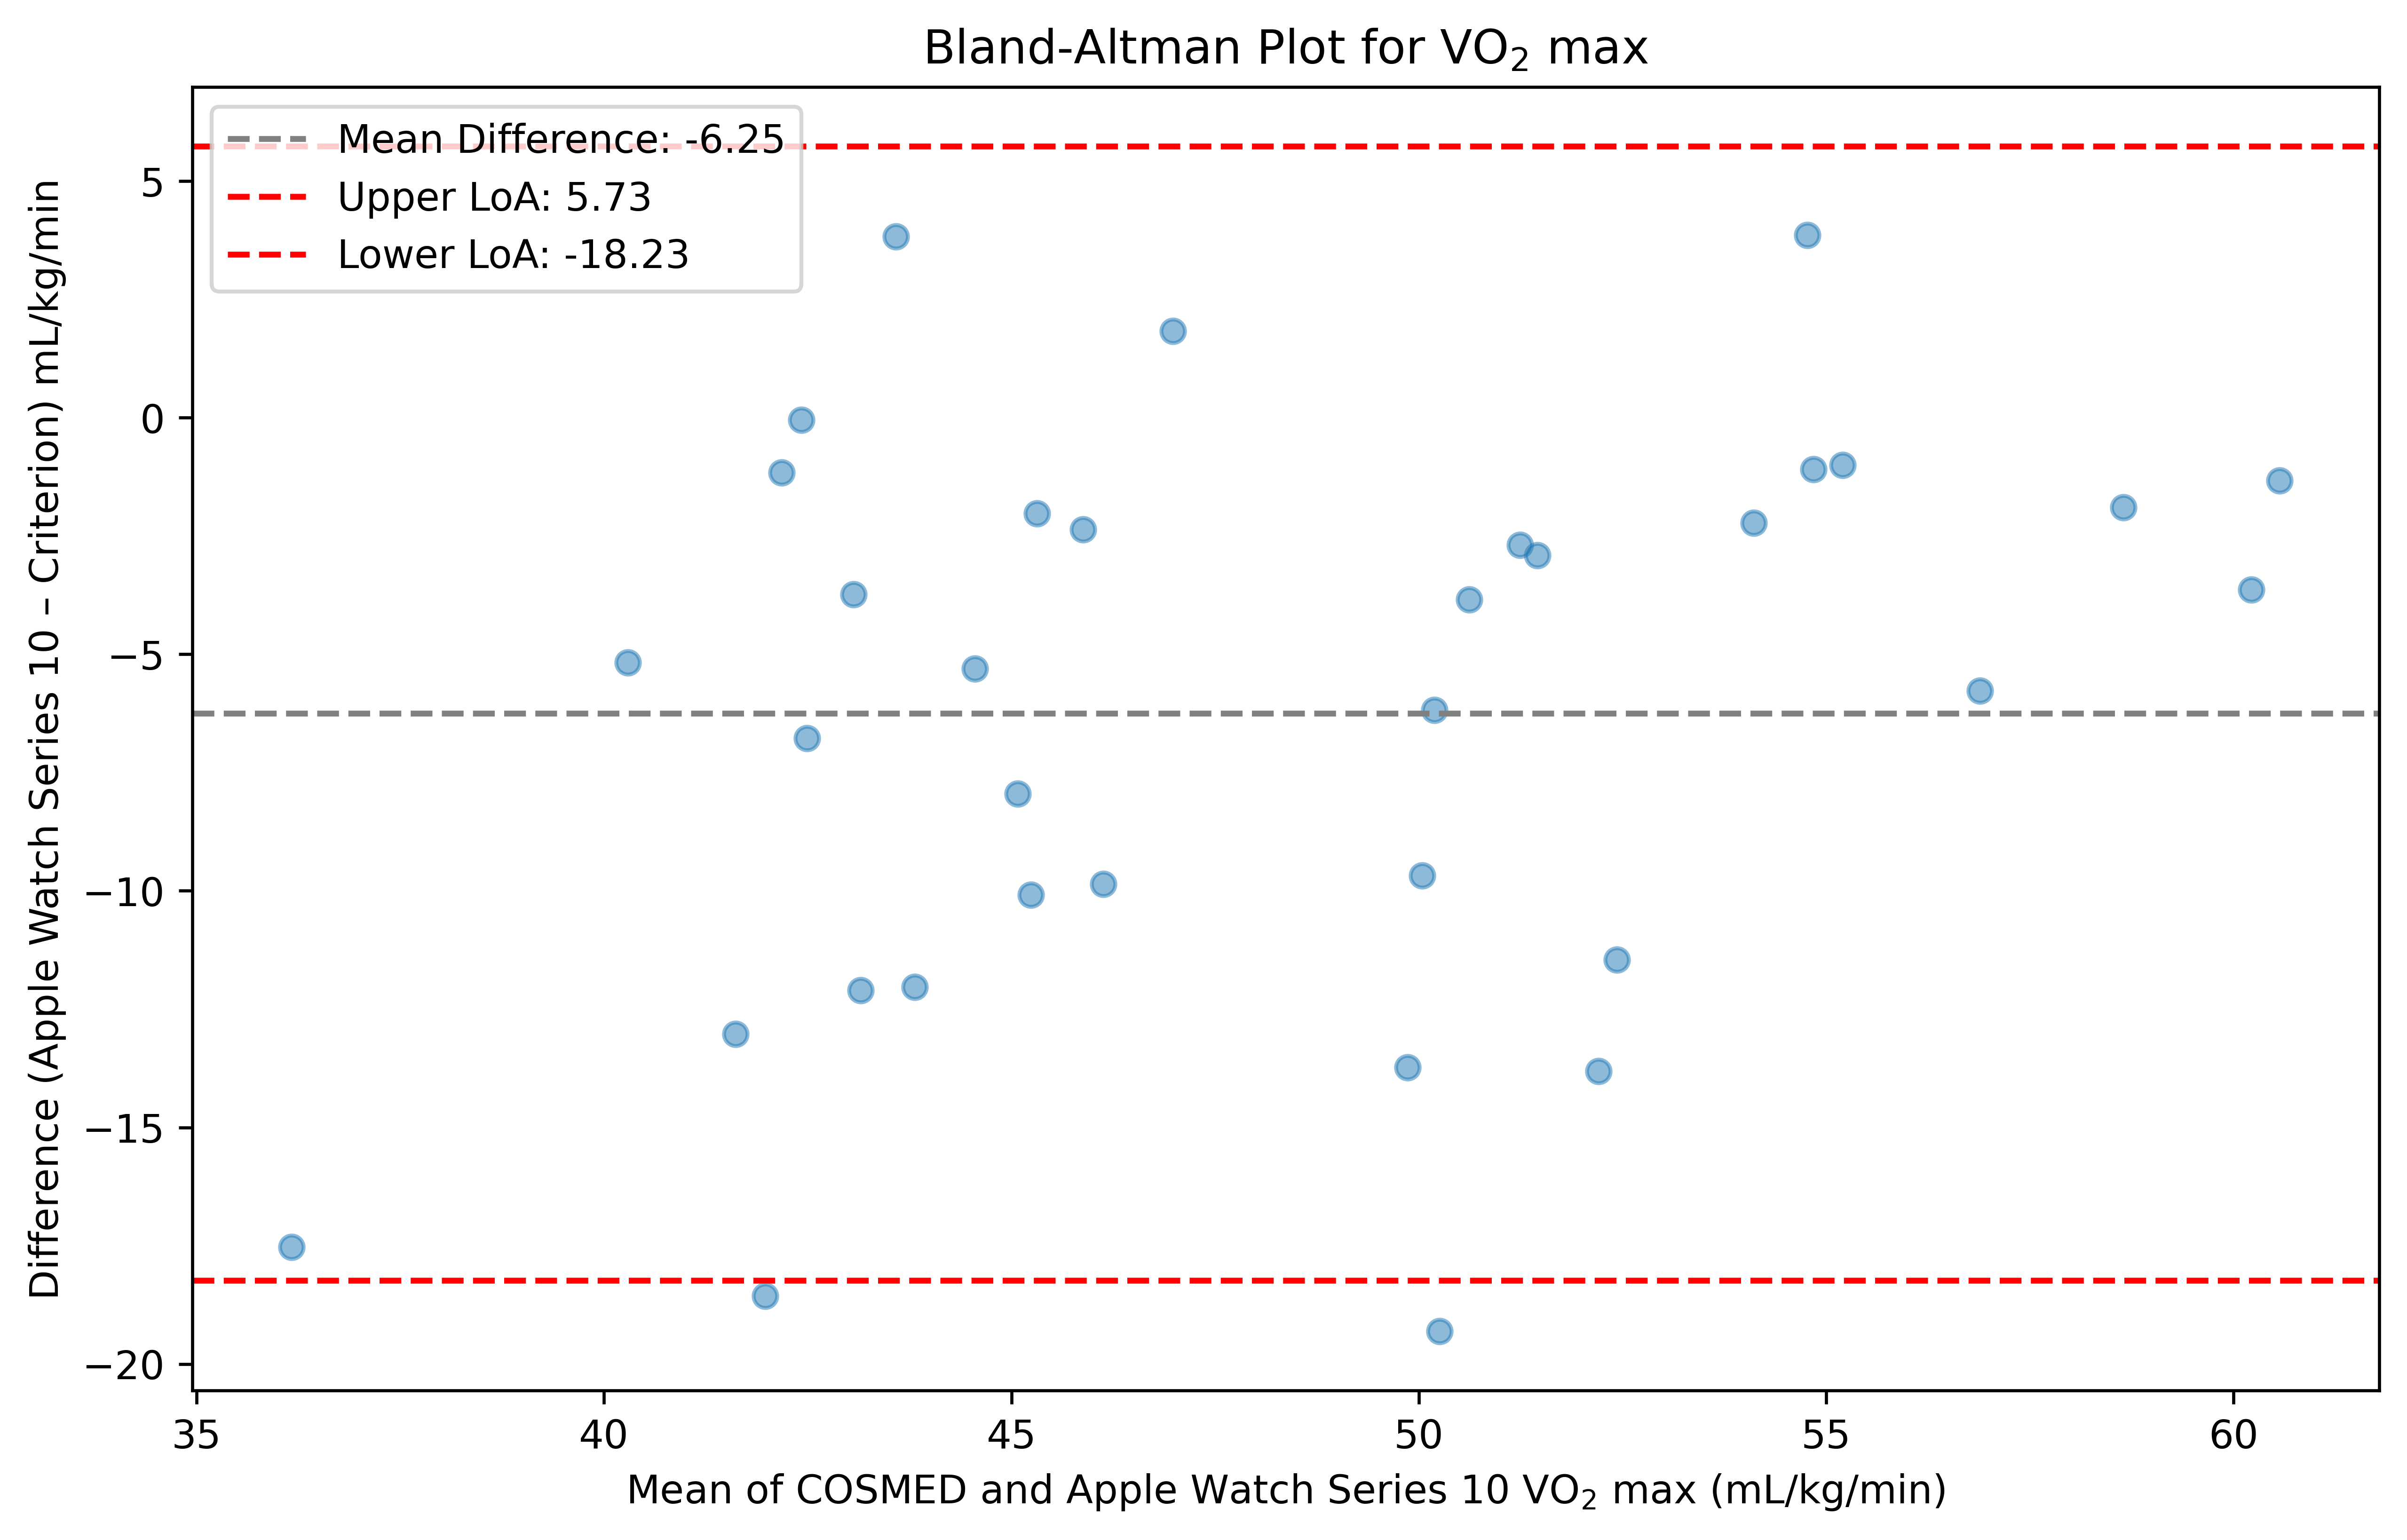

In [19]:
plt.rcParams['font.family'] = 'sans-serif'
plt.figure(figsize=(10, 6), dpi=600)
plt.scatter(mean_diff_values, diff, alpha=0.5)
plt.axhline(mean_diff, color='gray', linestyle='--', label=f'Mean Difference: {mean_diff:.2f}')
plt.axhline(loa_upper, color='red', linestyle='--', label=f'Upper LoA: {loa_upper:.2f}')
plt.axhline(loa_lower, color='red', linestyle='--', label=f'Lower LoA: {loa_lower:.2f}')
plt.title(f"Bland-Altman Plot for {metric_plot}")
plt.xlabel(f"Mean of COSMED and Apple Watch Series 10 {metric_plot} ({unit})")
plt.ylabel(f"Difference (Apple Watch Series 10 – Criterion) {unit}")
plt.legend()
# plt.savefig("applewatch_s10_blandAlt_plot_vo2max", dpi=1200)
plt.show()

## 3. Mean absolute percentage error (MAPE)

### MAPE function

Here is a handy function to calculate MAPE in a few lines of code. Below, the manual MAPE calculation preserves the underlying statistical steps.

In [20]:
def calculate_mape(criterion, index):
    criterion, index = np.array(criterion), np.array(index)
    return np.mean(np.abs((criterion - index) / criterion)) * 100

In [21]:
mape = calculate_mape(criterion, index)
print(f'MAPE: {mape:.4f} %')
print(f'Number of participants: {len(criterion)}')

MAPE: 13.1717 %
Number of participants: 35


#### Manual MAPE calculation

In [22]:
absolute_errors = (criterion - index).abs()

In [23]:
# Calculate absolute percentage errors
absolute_percentage_errors = (absolute_errors / criterion) * 100

In [24]:
# Sum the absolute percentage errors
sum_absolute_percentage_errors = absolute_percentage_errors.sum()

# Get the total number of data points
total_data_points = len(absolute_percentage_errors)

In [25]:
# Calculate MAPE
mape = sum_absolute_percentage_errors / total_data_points

In [26]:
# Calculate standard deviation and standard error for MAPE
std_percentage_error = absolute_percentage_errors.std()
n = len(absolute_percentage_errors)
se_percentage_error = std_percentage_error / np.sqrt(n)

We use t-critical values to calculate the 95% confidence intervals as our sample size is small. Alternatively, in a bigger sample, you may use the z-score approach.

In [27]:
# Calculate the t critical value for a 95% confidence level
t_critical = t.ppf(0.975, df=n-1)  # 0.975 corresponds to 95% two-tailed

# Calculate 95% CI for the MAPE
# ci_upper = mean_diff + 1.96 * se_diff_mae
# ci_lower = mean_diff - 1.96 * se_diff_mae

ci_upper = mape + (t_critical * se_percentage_error)
ci_lower = mape - (t_critical * se_percentage_error)

In [28]:
print(f"MAPE for {metric} is: {mape:.4f} %")
print(f"95% confidence intervals for the MAPE: {ci_lower:.2f}, {ci_upper:.2f}")
print(f"The standard error of the MAPE: {se_percentage_error:.2f}%")

MAPE for VO2 max is: 13.1717 %
95% confidence intervals for the MAPE: 9.56, 16.79
The standard error of the MAPE: 1.78%


## 4. Mean absolute error

Just like MAPE, we can calculate mean absolute error using ``sklearn``, but the manual method below show how it works under the hood.

#### Manual MAE calculation

In [29]:
# Divide the sum by the total number of data points
mae = absolute_errors.mean()
print(mae)

6.794571428571428


#### MAE from sklearn

In [30]:
from sklearn.metrics import mean_absolute_error

y_true = criterion
y_pred = index
mae = mean_absolute_error(y_true, y_pred)

print(f'MAE from scikit-learn: {mae}')

MAE from scikit-learn: 6.794571428571428


##### 95% CI for MAE

In [31]:
# ** CALCULATE 95% CONFIDENCE INTERVAL **
# Calculate the standard deviation of the absolute errors
std_dev = absolute_errors.std(ddof=1)

# Calculate the standard error of the mean (SEM)
n = len(absolute_errors)
sem = std_dev / np.sqrt(n)

# Determine the t-critical value for a 95% confidence interval
confidence = 0.95
degrees_freedom = n - 1
alpha = 1 - confidence
t_crit = stats.t.ppf(1 - alpha/2, degrees_freedom)

# Calculate the margin of error
# Usually, margin of error = 1.96 * sem, but for smaller populations, t_crit is more appropriate
margin_of_error = t_crit * sem

# Compute the 95% confidence interval
lower_bound = mae - margin_of_error
upper_bound = mae + margin_of_error

In [32]:
print(f"The Mean Absolute Error for {metric} is {mae:.4f} {unit}.")
print(f"The 95% confidence interval is ({lower_bound:.4f}, {upper_bound:.4f}) {unit}.")
print(f"t-critical value: {t_crit:.4f}")
print(f"The standard error of the differences is {sem:.2f} {unit}")

The Mean Absolute Error for VO2 max is 6.7946 mL/kg/min.
The 95% confidence interval is (4.9108, 8.6783) mL/kg/min.
t-critical value: 2.0322
The standard error of the differences is 0.93 mL/kg/min
